In [24]:
import pandas as pd
import os
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [6]:
path = Path(os.getcwd()) /  "../../data/hu4_esquizofrenia_limpio.csv"

# Con tld_unknown y sin tld_unknown

In [20]:
df = pd.read_csv(path)

DROP_COLUMNS = ['nregistro']
DROP_COLUMNS_TLD = ['tld_unknown', 'nregistro']

df_sin_nregistro = df.drop(columns=DROP_COLUMNS)

df_sin_TLD = df.drop(columns=DROP_COLUMNS_TLD)

# Prueba con kmeans
Vamos a probar con clusters de 2 a 12. Primero con ``df_sin_nregistro`` y después con ``df_sin_TLD``.

Como métricas de decisión, utilizamos:

- **La silueta:** mide el grado en el que cada punto del cluster está cerca de su cluster y lejos del cluster vecino.
- **La inercia:** suma de las distancias al cuadrado de cada punto al centroide. Siempre baja al añadir clusters,
        por eso nos fijamos en el codo, que es el punto en donde la inercia pasa de bajar rápidamente a bajar más despacio.

In [27]:

resultados = {}
print("\nKmeans sin nregistro:")
inercias, siluetas = [], []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10)
    etiquetas = km.fit_predict(df_sin_nregistro)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(df_sin_nregistro, etiquetas))
    print(k, km.inertia_, silhouette_score(df_sin_nregistro, etiquetas))
resultados["sin nregistro"] = (inercias, siluetas)

print("\nKmeans sin nregistro ni tld_unknown:")
inercias, siluetas = [], []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10)
    etiquetas = km.fit_predict(df_sin_TLD)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(df_sin_TLD, etiquetas))
    print(k, km.inertia_, silhouette_score(df_sin_TLD, etiquetas))
resultados["sin nregistro ni tld_unknown"] = (inercias, siluetas)    



Kmeans sin nregistro:
2 9147.221818180305 0.2554303260858876
3 7853.877986577865 0.21393102364591454
4 6806.15780281027 0.23511110133704102
5 6223.672322368904 0.2516959396670525
6 5801.53078066719 0.1620702980145377
7 5396.848103287188 0.16543487063953713
8 4969.525132120925 0.2162361709216559
9 4673.820167744972 0.18171693671551742
10 4398.8225734347225 0.19283392739566357
11 4251.84588195684 0.17968809241558792
12 4016.0752324276514 0.1865321590576423

Kmeans sin nregistro ni tld_unknown:
2 8949.559167577898 0.260281799355014
3 7636.229629935138 0.23865555958646
4 6609.10100250452 0.24094412823195333
5 6030.9058540671285 0.2615013348220672
6 5622.391687746712 0.16641593059853674
7 5200.429711382922 0.20650130131290168
8 4847.736632500624 0.1898276286108417
9 4502.322148711359 0.18230959529251126
10 4212.2171895297715 0.20408711284387707
11 3975.042727647214 0.20078001192856706
12 3789.668931754809 0.20672667672127745


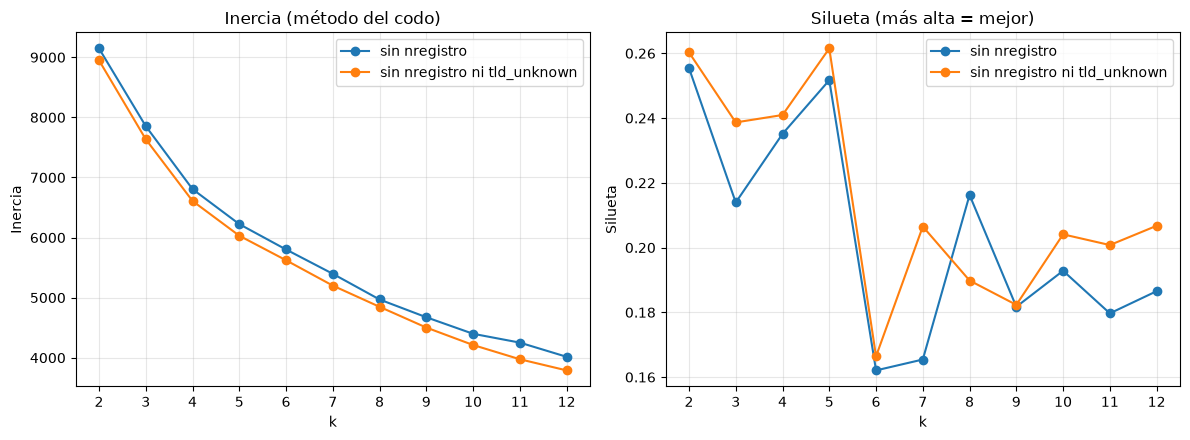

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ks = list(range(2, 13))
for nombre, (inercias, siluetas) in resultados.items():
    ax1.plot(ks, inercias, marker="o", label=nombre)
    ax2.plot(ks, siluetas, marker="o", label=nombre)

ax1.set_title("Inercia (método del codo)")
ax1.set_xlabel("k")
ax1.set_ylabel("Inercia")

ax2.set_title("Silueta (más alta = mejor)")
ax2.set_xlabel("k")
ax2.set_ylabel("Silueta")

for ax in (ax1, ax2):
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Conclusiones
## Inercia
La inercia baja rápidamente hasta 4-5 clústers. A partir del sexto clúster, la inercia desciende de manera más lenta.

## Silueta
La mejor silueta es la de 5 clústers sin ``nregistro`` ni ``tld_unknown``. 

## Decisión
Debido a la inercia y a la silueta, decidimos utilizar 5 clústers.